# Frente B, capítulo 2: husos de sueño (etapa 7)

**Módulo:** `descriptores/husos.py` · **Figuras:** `b_husos_*`

## De qué se trata

Los **husos de sueño** son ráfagas breves de actividad entre 11 y 16 Hz que duran entre
0,5 y 2 s. Se ven mejor en los electrodos centrales y son la marca característica de
N2: el manual AASM los usa para reconocer ese estadio. En REM prácticamente no hay.

Una época puede tener la misma potencia σ con un huso claro o con actividad dispersa.
Por eso, además de la potencia de la banda (capítulo 1), conviene **detectar cada huso**
y contarlos.

## El recorrido de la señal

```
EEG central (C4), toda la noche
   │
   ├─ pasa-banda de 11 a 16 Hz, sin desfase                  _envolvente()
   ├─ envolvente con la transformada de Hilbert
   ├─ suavizado de 0,2 s
   │
   ├─ umbral: media + 1,5 desvíos de la envolvente de la noche   _buscar_tramos()
   ├─ tramos que superan el umbral durante 0,5 a 2 s
   │
   └─ cada huso se asigna a la época donde cae su centro      descriptores_husos()
          └─ por época: cantidad de husos y amplitud media
```

## Entorno y datos

Los resultados de abajo se calcularon con un registro real de la base, SN122 (un
paciente de entrenamiento), y los números del texto son de ese paciente. Si no hay datos descargados, el notebook usa el registro
sintético de `comun/sintetico.py` y las figuras cambian.

Las señales llegan **preprocesadas** por el Frente A (`pipeline.preprocesar`): filtradas
entre 0,2 y 45 Hz con notch en 50 Hz, sin artefacto ocular (Wiener con compuerta) y sin
artefacto cardíaco. El EMG va con un pasa-altos de 10 Hz. La señal cruda queda en
`crudo` para comparar.

In [1]:
# Entorno común a todos los notebooks: se corre desde codigo/ para que DIR_DATOS
# ("data" o $ESTADIOS_DATOS) apunte al mismo lugar que los scripts.
import os
import sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

# Si el paquete no está instalado con `pip install -e .`, se usa directamente codigo/src.
# Las dependencias (numpy, scipy, pandas, matplotlib, mne) sí tienen que estar
# instaladas en el Python de este kernel.
try:
    import estadios  # noqa: F401
except ModuleNotFoundError:
    sys.path.insert(0, str(Path.cwd() / "src"))
FIGURAS = Path.cwd().parent / "informe" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt

from estadios.comun.config import Config
from estadios.comun.constantes import NOMBRES_ESTADIOS, N_ESTADIOS
from estadios.datos.carga import ids_disponibles

USAR_DATOS_REALES = len(ids_disponibles()) > 0
print("Datos reales" if USAR_DATOS_REALES else "Sin datos descargados: se usan los sintéticos")

Datos reales


In [2]:
# Estilo común de las figuras del Frente B. Cada estadio tiene siempre el mismo color.
COLOR_ESTADIO = dict(zip(NOMBRES_ESTADIOS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
GRIS, TINTA = "#8a8984", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRIS,
    "axes.labelcolor": TINTA,
    "axes.titlesize": 10,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "xtick.color": TINTA,
    "ytick.color": TINTA,
    "lines.linewidth": 1.5,
    "legend.frameon": False,
})


def guardar(fig, nombre):
    """Guarda la figura en informe/figuras/ para incluirla con \\includegraphics."""
    fig.savefig(FIGURAS / f"{nombre}.pdf", bbox_inches="tight")


def por_estadio(ax, valores, estadios, titulo, unidad=""):
    """Diagrama de caja de un descriptor en cada estadio, sin los valores extremos."""
    grupos = [valores[estadios == e] for e in range(N_ESTADIOS)]
    cajas = ax.boxplot(grupos, tick_labels=NOMBRES_ESTADIOS, showfliers=False,
                       patch_artist=True, widths=0.55,
                       medianprops={"color": TINTA, "linewidth": 1.5})
    for caja, nombre in zip(cajas["boxes"], NOMBRES_ESTADIOS):
        caja.set(facecolor=COLOR_ESTADIO[nombre], alpha=0.55, edgecolor=GRIS)
    ax.set(title=titulo, ylabel=unidad)
    ax.grid(axis="x", visible=False)

In [3]:
from estadios.comun.sintetico import preprocesado_sintetico
from estadios.datos.carga import cargar_registro
from estadios.pipeline import preprocesar

cfg = Config().descriptores
if USAR_DATOS_REALES:
    # La señal cruda se guarda para comparar; los descriptores usan la preprocesada.
    # SN122 es el paciente de ejemplo de los textos; si no está, se usa el primero.
    disponibles = ids_disponibles()
    crudo = cargar_registro("SN122" if "SN122" in disponibles else disponibles[0])
    prep = preprocesar(crudo, Config().preprocesamiento)
else:
    prep = preprocesado_sintetico(minutos=120)
    crudo = prep.registro

registro = prep.registro
fs = registro.fs
estadios_tecnicos = registro.estadios
print(f"{registro.id}: {registro.n_epocas} épocas de 30 s ({registro.n_epocas / 120:.1f} h)")
print({n: int((estadios_tecnicos == e).sum()) for e, n in enumerate(NOMBRES_ESTADIOS)})

SN122: 845 épocas de 30 s (7.0 h)
{'W': 66, 'N1': 67, 'N2': 303, 'N3': 288, 'R': 121}


## 1. Paso a paso sobre un huso

Se toma un tramo de 10 s de N2 que contiene un huso detectado y se muestra qué le pasa a
la señal en cada paso.

1. **Pasa-banda.** Un Butterworth de orden 4 entre 11 y 16 Hz deja solo la banda de los
   husos. Se aplica hacia adelante y hacia atrás (`sosfiltfilt`) para no desplazar la
   señal en el tiempo: si no, el huso detectado quedaría corrido respecto del real.
2. **Envolvente.** La transformada de Hilbert da la amplitud instantánea de la señal
   filtrada, una curva que sigue los máximos de la oscilación sin oscilar ella misma.
3. **Suavizado.** Un promedio móvil de 0,2 s evita que una caída momentánea de la
   envolvente parta un huso en dos.
4. **Umbral.** Se fija en la media más 1,5 desvíos de la envolvente de **toda la noche
   del paciente**. Al ser relativo al propio registro, sirve igual para pacientes con
   más o menos amplitud.
5. **Duración.** Se quedan los tramos sobre el umbral que duran entre 0,5 y 2 s. Los más
   cortos suelen ser ruido, y los más largos, otra actividad (por ejemplo, ritmo α).

Husos detectados en la noche: 935. Umbral: 13.4 µV.


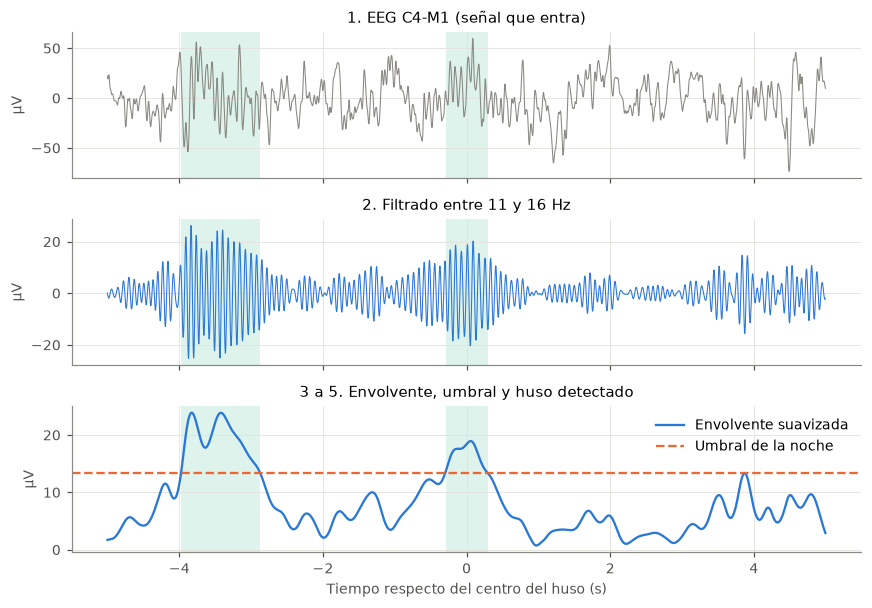

In [4]:
from estadios.comun.constantes import N2
from estadios.descriptores import husos
from scipy import signal

c4 = registro.senales[cfg.canal_husos]
filtrada = signal.sosfiltfilt(signal.butter(4, cfg.husos_banda_hz, "bandpass", fs=fs, output="sos"), c4)
envolvente = husos._envolvente(c4, fs, cfg.husos_banda_hz)
umbral = envolvente.mean() + husos.UMBRAL_DESVIOS * envolvente.std()
tramos = husos.detectar_husos(c4, fs, cfg.husos_banda_hz, cfg.husos_duracion_s)

# Un huso dentro de una época de N2, en el medio de la noche.
n_epoca = int(30 * fs)
en_n2 = [t for t in tramos if estadios_tecnicos[min(int(t.mean()) // n_epoca, registro.n_epocas - 1)] == N2]
inicio, fin = en_n2[len(en_n2) // 2]
centro = (inicio + fin) // 2
ventana = slice(centro - int(5 * fs), centro + int(5 * fs))
t = (np.arange(ventana.start, ventana.stop) - centro) / fs

fig, axs = plt.subplots(3, 1, figsize=(8, 5.6), sharex=True)
axs[0].plot(t, c4[ventana], color=GRIS, lw=0.7)
axs[0].set(title=f"1. {cfg.canal_husos} (señal que entra)", ylabel="µV")
axs[1].plot(t, filtrada[ventana], color=AZUL, lw=0.7)
axs[1].set(title="2. Filtrado entre 11 y 16 Hz", ylabel="µV")
axs[2].plot(t, envolvente[ventana], color=AZUL, label="Envolvente suavizada")
axs[2].axhline(umbral, color=NARANJA, ls="--", label="Umbral de la noche")
axs[2].set(title="3 a 5. Envolvente, umbral y huso detectado", ylabel="µV", xlabel="Tiempo respecto del centro del huso (s)")
axs[2].legend(loc="upper right")
for ax in axs:
    for a, b in tramos:
        if a < ventana.stop and b > ventana.start:
            ax.axvspan((a - centro) / fs, (b - centro) / fs, color=VERDE, alpha=0.15, lw=0)
fig.tight_layout()
guardar(fig, "b_husos_pasos")
print(f"Husos detectados en la noche: {len(tramos)}. Umbral: {umbral:.1f} µV.")

En el EEG que entra (arriba) el huso apenas se distingue del resto de la actividad. Al filtrar
aparece como una oscilación que crece y decrece, con la forma de huso que le da el
nombre, y la envolvente lo convierte en una loma que cruza el umbral. La franja verde
marca el tramo detectado.

## 2. Cuántos husos hay en cada estadio

`descriptores_husos()` cuenta, para cada época, los husos cuyo centro cae en ella, y
promedia su amplitud (el máximo de la envolvente en cada huso). Una época sin husos
vale 0 en los dos descriptores.

{'husos.cantidad': np.float64(1.1), 'husos.amplitud': np.float64(12.67)}


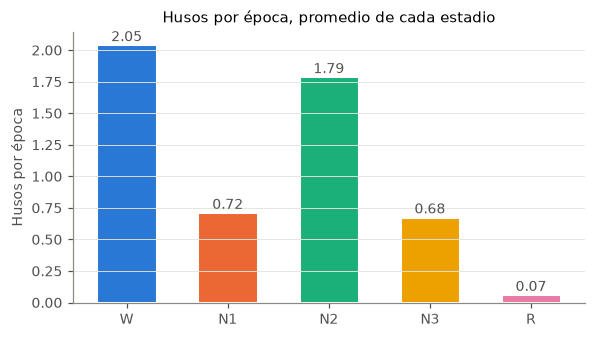

In [5]:
matriz, nombres = husos.descriptores_husos(prep, cfg)
cantidad = matriz[:, nombres.index("husos.cantidad")]

fig, ax = plt.subplots(figsize=(6, 3.2))
medias = [cantidad[estadios_tecnicos == e].mean() if (estadios_tecnicos == e).any() else 0 for e in range(N_ESTADIOS)]
ax.bar(NOMBRES_ESTADIOS, medias, color=[COLOR_ESTADIO[n] for n in NOMBRES_ESTADIOS], width=0.6, edgecolor="white", linewidth=2)
for x, m in enumerate(medias):
    ax.text(x, m, f"{m:.2f}", ha="center", va="bottom", color=TINTA)
ax.set(title="Husos por época, promedio de cada estadio", ylabel="Husos por época")
ax.grid(axis="x", visible=False)
guardar(fig, "b_husos_por_estadio")
print(dict(zip(nombres, matriz.mean(axis=0).round(2))))

REM casi no tiene husos (0,07 por época) y N2 tiene casi dos (1,8), como espera el
manual. Lo que no se espera es W, con 2,05 por época, más que N2. El detector no sabe
de estadios, solo busca tramos con más energía entre 11 y 16 Hz que el resto de la
noche, y algo en la vigilia de este paciente cumple esa condición.

### Husos en vigilia: ¿qué detecta el algoritmo en W?

Para ver si lo que aparece en W es un huso o es otra cosa se hacen dos comparaciones.
La primera es contar los husos sobre la señal cruda y sobre la preprocesada, para ver
si el filtrado y la remoción de artefactos del Frente A cambian algo. La segunda es
medir la **frecuencia** de cada detección, contando cuántas veces la señal filtrada
cruza el cero dentro del tramo. Un huso de N2 oscila entre 12 y 14 Hz. El ritmo α de
vigilia oscila entre 8 y 13 Hz, y su parte alta cae dentro de la banda de 11 a 16 Hz
del detector.

,"Husos por época, señal cruda","Husos por época, preprocesada",Frecuencia mediana (Hz)
W,2.02,2.05,13.11
N1,0.79,0.72,13.33
N2,1.85,1.81,12.96
N3,0.71,0.68,12.73
R,0.07,0.07,12.37


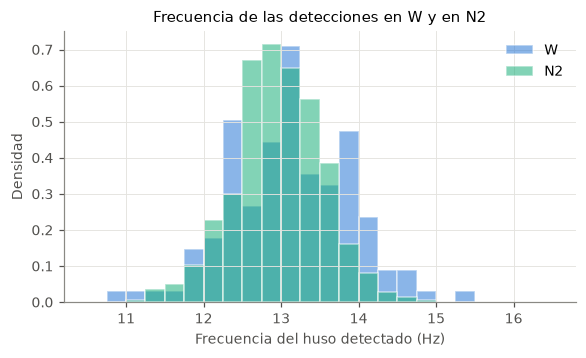

In [6]:
import pandas as pd

def husos_por_epoca(tramos):
    centros = np.minimum(tramos.mean(axis=1).astype(int) // n_epoca, registro.n_epocas - 1)
    return np.bincount(centros, minlength=registro.n_epocas)

def frecuencia(senal_filtrada, tramos):
    """Cruces por cero dentro de cada tramo, divididos por dos veces su duración."""
    signo = np.signbit(senal_filtrada)
    return np.array([np.count_nonzero(signo[a + 1:b] != signo[a:b - 1]) / (2 * (b - a) / fs) for a, b in tramos])

tramos = np.asarray(tramos).reshape(-1, 2)
tramos_crudo = np.asarray(husos.detectar_husos(
    crudo.senales[cfg.canal_husos], fs, cfg.husos_banda_hz, cfg.husos_duracion_s)).reshape(-1, 2)
f_prep = frecuencia(filtrada, tramos)
estadio_prep = estadios_tecnicos[np.minimum(tramos.mean(axis=1).astype(int) // n_epoca, registro.n_epocas - 1)]

comparacion = pd.DataFrame({
    "Husos por época, señal cruda": [husos_por_epoca(tramos_crudo)[estadios_tecnicos == e].mean() for e in range(N_ESTADIOS)],
    "Husos por época, preprocesada": [husos_por_epoca(tramos)[estadios_tecnicos == e].mean() for e in range(N_ESTADIOS)],
    "Frecuencia mediana (Hz)": [np.median(f_prep[estadio_prep == e]) if (estadio_prep == e).any() else np.nan for e in range(N_ESTADIOS)],
}, index=NOMBRES_ESTADIOS).round(2)
display(comparacion)

fig, ax = plt.subplots(figsize=(6, 3.2))
bordes = np.arange(10.5, 16.6, 0.25)
for e, nombre in enumerate(NOMBRES_ESTADIOS):
    if nombre in ("W", "N2"):
        ax.hist(f_prep[estadio_prep == e], bins=bordes, density=True, alpha=0.55,
                color=COLOR_ESTADIO[nombre], label=nombre, edgecolor="white")
ax.set(xlabel="Frecuencia del huso detectado (Hz)", ylabel="Densidad", title="Frecuencia de las detecciones en W y en N2")
ax.legend()
guardar(fig, "b_husos_frecuencia")

El preprocesamiento del Frente A no cambia casi nada (de 2,02 a 2,05 husos por época en
W, y de 1,85 a 1,81 en N2). Era esperable, porque sus filtros no tocan la banda de 11 a
16 Hz y los artefactos que quita son lentos (el ocular) o muy breves (el cardíaco).

La frecuencia tampoco separa las detecciones de W de las de N2, ya que las dos tienen
una mediana cercana a 13 Hz. Así que no se trata de la parte alta del ritmo α, que
tendría que dar detecciones cerca de 11 Hz. Una ráfaga de banda ancha, como la de un
movimiento o la de un músculo que se tensa, también oscila en el centro de la banda
cuando se la pasa por el filtro, y por eso la frecuencia no ayuda a distinguirla.

Si las detecciones de W vinieran de movimientos o de tensión muscular, las épocas de W
con muchos "husos" tendrían que tener el EMG más alto que las que no tienen ninguno. Si
vinieran del ritmo α de la vigilia relajada, tendrían que tener más α en O2.

In [7]:
from scipy.stats import spearmanr
from estadios.comun.constantes import EEG_O2, W
from estadios.descriptores import espectro, perifericos
from estadios.preprocesamiento.segmentacion import segmentar

m_per, n_per = perifericos.descriptores_perifericos(prep, cfg)
emg = 10 ** m_per[:, n_per.index("perifericos.amplitud_emg")]  # El descriptor está en log10.
f, psd = espectro.psd_multitaper(segmentar(registro.senales[EEG_O2], fs, registro.n_epocas), fs,
                                 cfg.multitaper_nw, cfg.multitaper_k)
bandas = espectro.potencia_bandas(f, psd, {"alfa": (8, 13), "total": (0.5, 30)})
alfa_o2 = bandas["alfa"] / bandas["total"]

conteo = husos_por_epoca(tramos)
en_w = estadios_tecnicos == W
grupos_w = {"W con 2 o más husos": en_w & (conteo >= 2), "W sin husos": en_w & (conteo == 0)}
display(pd.DataFrame({
    "Épocas": [g.sum() for g in grupos_w.values()],
    "EMG, mediana (µV RMS)": [np.median(emg[g]) for g in grupos_w.values()],
    "α relativa en O2, mediana": [np.median(alfa_o2[g]) for g in grupos_w.values()],
}, index=list(grupos_w)).round(2))
print(f"Correlación de Spearman entre husos por época y EMG, solo en W: {spearmanr(conteo[en_w], emg[en_w])[0]:.2f}")

,Épocas,"EMG, mediana (µV RMS)","α relativa en O2, mediana"
W con 2 o más husos,26,20.88,0.19
W sin husos,32,11.20,0.32


Correlación de Spearman entre husos por época y EMG, solo en W: 0.45


Las épocas de W con dos o más detecciones tienen un EMG casi del doble (21 contra
11 µV) y menos α en O2 (0,19 contra 0,32) que las épocas de W sin detecciones, y en W la
cantidad de detecciones crece junto con el EMG (Spearman de 0,45). Lo que el detector
encuentra en W son entonces ráfagas de la vigilia activa, con movimiento y tensión
muscular, y no husos ni ritmo α.

Esto le importa al Frente C. Su regla de W pide EMG alto y, además, α alta o parpadeos. Estas épocas tienen el EMG alto pero poca α, así que solo entran en W si hay parpadeos. Si no, y tampoco cumplen la de N3 ni la de REM, la regla de N2 las toma por sus "husos". Una forma de evitarlo sería que un EMG muy alto alcance para asignar W aunque falten la α y los parpadeos.

## 3. Lo que sale de este capítulo

Dos descriptores por época: `husos.cantidad` y `husos.amplitud`. Los parámetros que el
anteproyecto no fija (el factor 1,5 del umbral y el suavizado de 0,2 s) están como
constantes al principio de `husos.py` y siguen a Mölle et al. (2002).